# 03 · Parameter grid smoke result (S2, partial, development windows)

The real driver ran for 24 configurations × 2 scenarios on each completed development window. The grid was **stopped early**; only the windows whose groups finished are included. Results are selected-trade economics after costs.

**Labels on every number.** Outcomes are `proxy_outcome` labels (single positive payout entry, payout unit unknown). K is PROVISIONAL (exact-start TWAP tick, no attestation). The reference is the warehouse PolyBolt TWAP, not live RTDS. Execution follows named, uncalibrated scenarios; fees are the scenario curve. These are small samples from three recording sessions: diagnostics, not validated profitability.

In [1]:
# Reload edited project code (explorer, timelines, staged...) before each cell runs,
# so code changes apply without restarting the kernel.
%load_ext autoreload
%autoreload 2

import json

import pandas as pd

from tyrex_pm.research.strategy_lab import analysis
from tyrex_pm.research.strategy_lab.experiments import REPO

pd.set_option('display.width', 160)
S2 = REPO / 'var' / 'research' / 'strategy_runs' / 's2'
split = json.loads((S2 / 'split' / 'split.json').read_text())
print(len(split['development']), 'development windows;', len(split['holdout']),
      'holdout windows (not evaluated)')

45 development windows; 18 holdout windows (not evaluated)


In [2]:
grid = pd.read_parquet(S2 / 'grid' / 'summaries_partial.parquet')
print(grid['market_id'].nunique(), 'windows,', len(grid), 'runs')
econ = analysis.flatten_config(analysis.trade_economics(grid))
cols = ['scenario_name', 'model.backend', 'entry.min_edge_per_share', 'entry.tau_max_s',
        'sizing.max_debit_usdc', 'entries', 'fills', 'wins', 'total_debit', 'total_pnl',
        'pnl_per_debit', 'pnl_ci95_low', 'pnl_ci95_high']
econ[cols].sort_values(['scenario_name', 'pnl_per_debit'],
                       ascending=[True, False]).round(2)

9 windows, 432 runs


,scenario_name,model.backend,entry.min_edge_per_share,entry.tau_max_s,sizing.max_debit_usdc,entries,fills,wins,total_debit,total_pnl,pnl_per_debit,pnl_ci95_low,pnl_ci95_high
38,favorable,twap_proxy_diffusion,0.08,150.0,5,1,1,1,5.00,0.46,0.09,0.00,1.38
14,favorable,twap_proxy_diffusion,0.02,240.0,5,2,2,1,9.99,-3.60,-0.36,-14.98,4.16
10,favorable,endpoint_diffusion,0.02,240.0,5,8,8,3,39.98,-16.28,-0.41,-39.34,7.43
22,favorable,twap_proxy_diffusion,0.05,150.0,5,2,2,1,9.99,-4.54,-0.45,-14.99,1.38
30,favorable,twap_proxy_diffusion,0.05,240.0,5,2,2,1,9.99,-4.54,-0.45,-14.99,1.38
46,favorable,twap_proxy_diffusion,0.08,240.0,5,2,2,1,10.00,-4.54,-0.45,-15.00,1.38
6,favorable,twap_proxy_diffusion,0.02,150.0,5,2,2,1,9.99,-4.70,-0.47,-14.99,0.89
26,favorable,endpoint_diffusion,0.05,240.0,5,7,7,2,34.98,-16.91,-0.48,-39.98,6.46
42,favorable,endpoint_diffusion,0.08,240.0,5,7,7,2,34.98,-16.91,-0.48,-39.98,6.46
2,favorable,endpoint_diffusion,0.02,150.0,5,7,7,2,34.98,-20.23,-0.58,-39.99,-0.47


## Pooled by backend and scenario

In [3]:
pooled = econ.groupby(['scenario_name', 'model.backend'])[
    ['entries', 'fills', 'wins', 'total_debit', 'total_pnl']].sum()
pooled.assign(pnl_per_debit=pooled.total_pnl / pooled.total_debit).round(3)

entries  fills  wins  total_debit  total_pnl  pnl_per_debit
scenario_name model.backend                                                                    
favorable     endpoint_diffusion         76     76    16      280.874   -163.944         -0.584
              twap_proxy_diffusion       11     11     6       54.958    -21.463         -0.391
friction      endpoint_diffusion         74      9     0       24.342    -24.342         -1.000
              twap_proxy_diffusion       10      1     0        4.998     -4.998         -1.000

## Which side the strategy buys

In [4]:
filled = grid[grid['filled'] == True]  # noqa: E712 - boolean column
up, down = filled['side'] == 'UP', filled['side'] == 'DOWN'
book_up = filled['book_implied_up_at_entry']
underdog = (up & (book_up < 0.5)) | (down & (book_up > 0.5))
print(f'{underdog.mean():.0%} of fills bought the side the book priced below 0.5;'
      f' win rate {(filled.realized_pnl > 0).mean():.0%};'
      f' mean price {filled.vwap.mean():.3f}')

71% of fills bought the side the book priced below 0.5; win rate 23%; mean price 0.441


## Skip and decision reasons

In [5]:
reasons: dict[str, int] = {}
for counts in grid['entry_reason_counts']:
    for key, n in json.loads(counts).items():
        reasons[key] = reasons.get(key, 0) + n
pd.Series(reasons).sort_values(ascending=False).head(15)

HOST_SKIPPED:exact_candidate_absent,incomplete_fallback_candidates    129960
WAIT:OUTSIDE_ENTRY_BAND                                                35688
HOST_SKIPPED:future_binance_rejected,threshold_not_configured          27816
WAIT:EDGE_BELOW_COST                                                   21395
HOLD:HOLDING_TO_SETTLEMENT                                             15852
WAIT:EPISODE_CONSUMED                                                  14561
SKIP:ENTRY_WINDOW_CLOSED                                               12250
WAIT:DEPTH_INSUFFICIENT                                                12029
WAIT:BELOW_MINIMUM_SIZE                                                 1431
WAIT:MODEL_NOT_READY                                                     527
HOST_SKIPPED:exact_candidate_absent                                      432
ENTER:EDGE_CLEARS_COST                                                   171
WAIT:BOOK_NOT_READY                                                      119

## Stability ranking (development only)

In [6]:
axes = ['model.backend', 'entry.min_edge_per_share', 'entry.tau_max_s',
        'sizing.max_debit_usdc']
scores = analysis.neighbour_scores(analysis.trade_economics(grid), axes=axes,
                                   scenario='friction', min_fills=5)
scores  # empty: no configuration reaches 5 fills under friction on this sample

,config,fills,pnl_per_debit,neighbourhood_mean,neighbourhood_min,neighbours


## Reading

* Every configuration loses on these windows, under both scenarios. The 95% window-bootstrap intervals are wide but sit mostly below zero.
* Most fills buy the side the book prices as the underdog: the model disagrees with the book and the book was right more often, consistent with notebook 02.
* Under `friction` with no limit buffer, most taker orders do not fill: the adverse tick never pays beyond the limit. `entry.limit_buffer_ticks` addresses that.
* No shortlist was produced and the holdout was **not** evaluated.

<!-- results-explorer -->
# Results explorer

The cells above summarise the partial grid in tables. This section lets you **look inside** the saved results, one configuration at a time.

It is a viewer, not a simulator. It reads saved summary files, and it never reruns the strategy, connects to a feed or places an order. Each file is loaded once; every control just filters the table already in memory.

**Path through the explorer:** choose dataset → choose execution scenario → compare configurations → select one configuration → inspect its windows.

**Two datasets, never combined:**

| Dataset | File | What it is |
|---|---|---|
| Corrected model comparison | `s2/validation_seed/summaries.parquet` | Two model backends after the clock correction, with a one-tick limit buffer. The primary evidence. |
| Partial parameter grid | `s2/grid/summaries_partial.parquet` | 24 configurations on the few windows that finished before the grid was stopped. Predates the clock correction. Smoke result only. |

The counts printed below are calculated from the files, not typed in.

**One configuration is still one configuration.** A configuration replayed on 45 windows under two scenarios gives 90 rows, but it is still a single set of settings tried on a single market history. Both scenarios replay the *same* windows, so a `favorable` row and a `friction` row are not two independent outcomes.

The first part is a **static walkthrough** that stays readable without a running kernel. The **interactive explorer** comes after it and needs one.

In [7]:
# results-explorer: load each saved dataset once (read-only)
from IPython.display import HTML, display

from tyrex_pm.research.strategy_lab import explorer as ex

datasets = {}
for key, spec in ex.DATASETS.items():
    try:
        datasets[key] = ex.load_dataset(key)
        display(HTML(ex.scope_html(datasets[key])))
    except FileNotFoundError as exc:
        print('Unavailable:', exc)

## Metric definitions

These are used in every table and chart below:

* **Entry request:** the strategy sent an order in that window. **Filled trade:** at least part of it filled.
* **Skipped window:** no order was sent. **Unfilled request:** an order was sent but nothing filled. **Neither is a trading loss.** They are counted separately and contribute nothing to profit or loss.
* **Unknown outcome:** a fill whose realized P&L is missing. It is excluded from P&L totals and win rate, and **it is not counted as zero.** (Neither saved file has any at present, but the explorer still marks them with `?`.)
* **Win rate** = profitable filled trades ÷ filled trades with a known realized P&L.
* **Net P&L** = simulated payout after fees minus acquisition spending, using **proxy** outcome labels, in USDC.
* **Acquisition spending** = filled shares × fill price, summed.
* **Net P&L ÷ spending** = net P&L ÷ spending on the trades whose P&L is known. It is **not** annualized and **not** a return on the whole account.
* **Expected profit at entry** (`ev_point`, `ev_conservative`) and **conservative probability** (`p_conservative`) are the model's own estimates, recorded when it decided to buy. They describe the **intended** purchase. A partial fill or a different fill price changes what was actually bought, so they are not an exact forecast for the filled position. `p_conservative` is a cautious model estimate for the chosen side, **not** a calibrated win rate.

These definitions differ from `analysis.trade_economics` above in one respect: that function counts a missing P&L as zero. The explorer keeps it unknown.

## Walkthrough: corrected model comparison, `friction`

### Chart 1: compare configurations (bars)

* **Question:** across the configurations in one dataset and one scenario, which ones made or lost the most simulated money, and on how many trades?
* **Reading it:**
  * One bar per configuration. The x-axis is the chosen metric, and the black line is zero.
  * **Blue** bars are above zero. **Orange, hatched** bars are below zero.
  * Faded bars have fewer than 10 resolved fills (*small sample*).
  * The grey column on the right prints the value and the number of fills. `▶` and bold text mark the selected configuration.
* **Look first** at the fills column: a bar resting on 1–2 trades says almost nothing.
* **What it cannot show:** whether any difference is real rather than luck. It also can't show *why* a configuration did better. The windows are shared and few, so the ranking is not a recommendation.

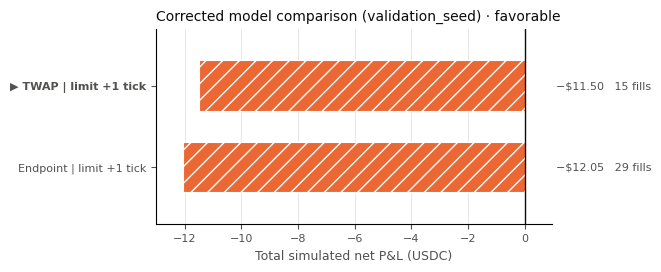

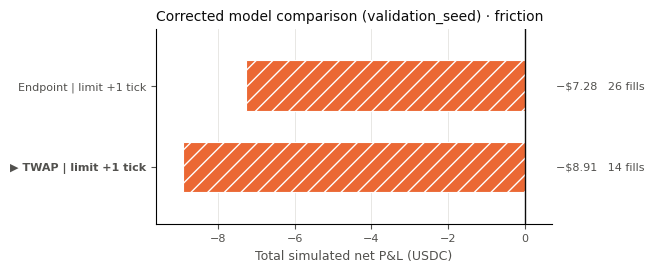

,label,windows,entry_requests,fills,unfilled,skipped,wins,losses,win_rate,spending,net_pnl,return_on_spending
0,Endpoint | limit +1 tick,45,30,26,4,15,9,17,0.346,128.953,-7.279,-0.056
1,TWAP | limit +1 tick,45,16,14,2,29,8,6,0.571,66.196,-8.909,-0.135


In [8]:
# results-explorer: static comparison, both scenarios kept separate
import matplotlib.pyplot as plt

seed = datasets.get('validation_seed')
if seed is None:
    print('Corrected model comparison is unavailable; skip this walkthrough.')
else:
    twap = seed.configs.loc[seed.configs['label'].str.startswith('TWAP'), 'config_id'].iloc[0]
    for scenario in seed.scenarios:
        fig = ex.plot_comparison(ex.comparison(seed, scenario), 'net_pnl', selected=twap,
                                 title=f'{seed.spec.title} · {scenario}')
        plt.show()
    display(ex.comparison(seed, 'friction')[
        ['label', 'windows', 'entry_requests', 'fills', 'unfilled', 'skipped', 'wins',
         'losses', 'win_rate', 'spending', 'net_pnl', 'return_on_spending']].round(3))

### The selected configuration: summary and saved overrides

The overrides table lists **only the settings saved with the run**. Every other setting came from the code defaults at the time of the run. Those defaults were not recorded, and the explorer does not fill them in from today's defaults.

In [9]:
# results-explorer: one configuration, one scenario
if seed is not None:
    rows = ex.windows_for(seed, twap, 'friction')
    metrics = ex._metrics(rows)
    print(seed.configs.set_index('config_id').loc[twap, 'label'], '· friction')
    display(ex.overrides_table(seed, twap))
    display(ex.summary_table(metrics))

TWAP | limit +1 tick · friction


,Value
Saved override,
entry.limit_buffer_ticks,1
model.backend,twap_proxy_diffusion


,Value,Meaning
Metric,,
Windows tested,45,Market windows replayed with this configuration.
Entry requests,16,Windows where the strategy sent an order.
Filled trades,14,Entry requests with at least some fill.
Unfilled entry requests,2,"Order sent, nothing filled. Not a loss."
Skipped windows,29,No order sent. Not a loss.
Fills with unknown P&L,0,Excluded from P&L; not zero.
Profitable / losing / break-even,8 / 6 / 0,Among fills with known P&L.
Win rate,57%,Profitable ÷ fills with known P&L.
Acquisition spending,$66.20,Sum of filled quantity × fill price.


### Chart 2: window by window

* **Question:** for this configuration, *when* did it trade, and how did each trade end?
* **Reading it:**
  * One slot per window, left to right in time (UTC start).
  * The bar height is the simulated net P&L of that window's trade. Blue bars won and orange, hatched bars lost.
  * Symbols on the zero line mark windows with no trade: `○` skipped (no order sent) and `×` order sent but nothing filled. A `◆` marks a break-even fill and `?` a fill with an unknown outcome.
  * The legend gives a count for each.
* **Look first** at how many slots are empty. Then compare the size of typical losses with typical wins.
* **What it cannot show:** what happened *inside* a window. This chart has one number per window. The table under it gives everything saved in the summary row, including how often each decision reason occurred. Chart 2b looks inside one window, where a timeline exists.

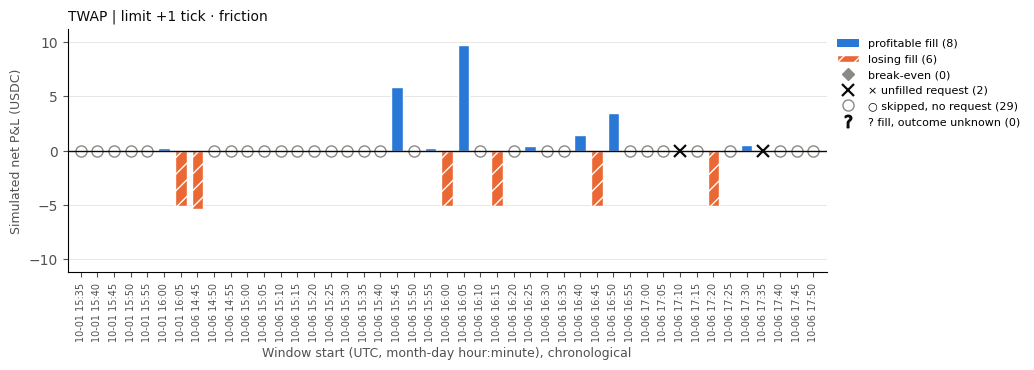

First losing window:


,Value
Field,
Window (UTC start),2026-10-01 16:05
Market,btc-updown-5m-1790870700
Market id,polymarket:condition:0xf6e19149d44913cf2f1c057...
Result,losing
Selected side,UP
"Entry decision, seconds remaining",181 s
Conservative probability (model estimate),0.846
Book-implied UP at entry,0.785
Limit price,0.800


,evaluations
decision reason,
"HOST_SKIPPED:exact_candidate_absent,incomplete_fallback_candidates",301
"HOST_SKIPPED:future_binance_rejected,threshold_not_configured",163
HOLD:HOLDING_TO_SETTLEMENT,72
WAIT:OUTSIDE_ENTRY_BAND,59
WAIT:EDGE_BELOW_COST,30
WAIT:MODEL_NOT_READY,3
HOST_SKIPPED:exact_candidate_absent,1
ENTER:EDGE_CLEARS_COST,1
HOLD:HOLD_TO_SETTLEMENT,1


First profitable window:


,Value
Field,
Window (UTC start),2026-10-01 16:00
Market,btc-updown-5m-1790870400
Market id,polymarket:condition:0xf921dd6878531692a639126...
Result,profitable
Selected side,UP
"Entry decision, seconds remaining",150 s
Conservative probability (model estimate),0.972
Book-implied UP at entry,0.935
Limit price,0.950


,evaluations
decision reason,
"HOST_SKIPPED:exact_candidate_absent,incomplete_fallback_candidates",301
"HOST_SKIPPED:future_binance_rejected,threshold_not_configured",169
HOLD:HOLDING_TO_SETTLEMENT,115
WAIT:OUTSIDE_ENTRY_BAND,27
WAIT:EDGE_BELOW_COST,16
HOST_SKIPPED:exact_candidate_absent,1
ENTER:EDGE_CLEARS_COST,1
HOLD:HOLD_TO_SETTLEMENT,1


In [10]:
# results-explorer: chronological windows and one example of each outcome
if seed is not None:
    label = seed.configs.set_index('config_id').loc[twap, 'label']
    ex.plot_windows(rows, title=f'{label} · friction')
    plt.show()
    for status in ('loss', 'win'):
        pick = rows[rows['status'] == status]
        if pick.empty:
            print(f'No {status} in this selection.')
            continue
        fields, reasons = ex.window_detail(pick.iloc[0])
        print(f'First {ex.STATUS_TEXT[status]} window:')
        display(fields, reasons.to_frame())

### Chart 2b: model probability vs book inside one window

* **Question:** in this window, what did the model believe, what was the market price, and when did the strategy ask to buy?
* **Reading it:** two panels share one time axis (UTC), from the window opening to 30 s after it closes.
  * **Top panel (Up):** solid blue is the model's point probability that Up wins. Dashed green is its *conservative* probability, the cautious bound the strategy trades on. The red line is the Up book midpoint, (bid + ask) / 2.
  * **Bottom panel (Down):** the same curves for Down. The point estimate mirrors Up (1 − Up). The conservative one is 1 − Up's *high* bound, so the two conservative values add up to less than 1. The Down midpoint comes from the Down book itself.
  * **The strip below:** the strategy's action each second. Grey hatching marks seconds the host skipped because inputs were unavailable. Lines join real evaluations up to 10 s apart and break at longer outages.
* **Markers:** ▲ is the ENTER *request*, drawn at the model's conservative probability. It is not a fill and not a venue acceptance. This dataset saved no fill timestamps, so the fill outcome is written in the title rather than drawn at an invented time.
* **Look first** at the gap between the conservative curve and the midpoint at the ▲: that gap is the edge the model believed it had.
* **What it cannot show:**
  * The midpoint is a price, not a verified probability, and a buyer pays the ask (more).
  * After entry the strategy holds to settlement and makes one entry per window, so later probability changes trigger no purchase.
  * The outcome is a proxy label.

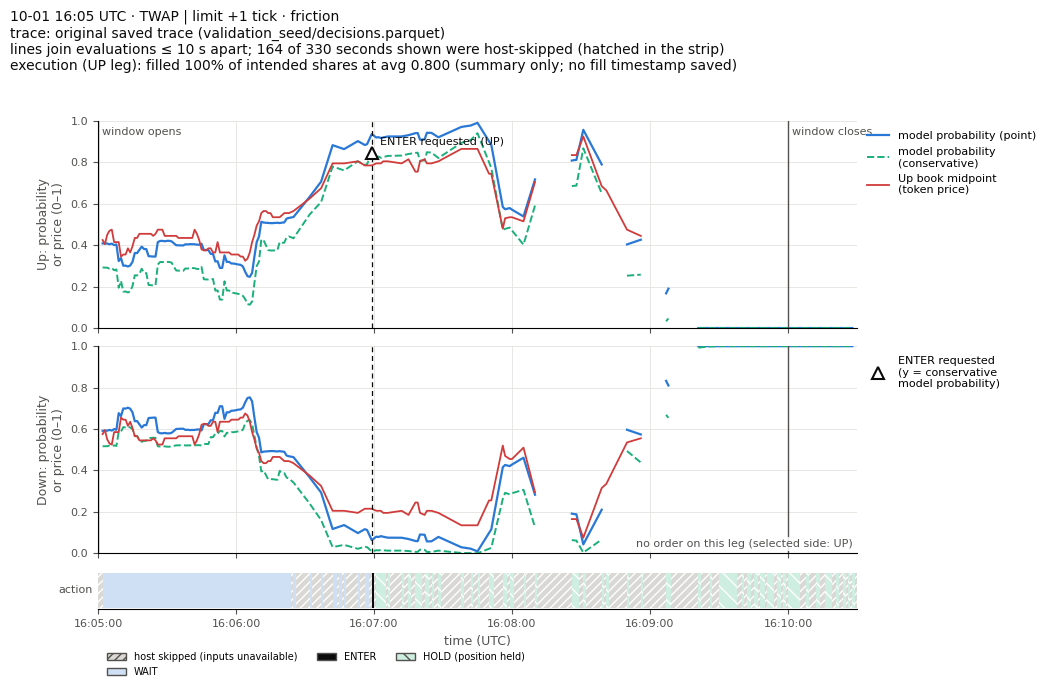

,evaluations
"HOST_SKIPPED: future_binance_rejected,threshold_not_configured",147
WAIT: OUTSIDE_ENTRY_BAND,59
HOLD: HOLDING_TO_SETTLEMENT,58
WAIT: EDGE_BELOW_COST,30
WAIT: MODEL_NOT_READY,3
"HOST_SKIPPED: exact_candidate_absent,incomplete_fallback_candidates",2


In [11]:
# results-explorer: probability vs book in the first losing window (saved trace, no replay)
from tyrex_pm.research.strategy_lab import timelines

if seed is not None:
    pick = rows[rows['status'] == 'loss']
    if pick.empty:
        pick = rows[rows['filled']]
    trace = None if pick.empty else timelines.get_trace(seed, pick.iloc[0])   # never replays
    if trace is None:
        print('No saved timeline for this selection.')
    else:
        row = pick.iloc[0]
        timelines.plot_timeline(trace, row, title=f"{row['window_label']} UTC · {label} · friction")
        plt.show()
        display(timelines.reason_counts(trace, row).to_frame())

### Chart 3: this configuration's profit/loss distribution

* **Bars (chart 1) and histogram:** the bars compare *many configurations* by one number each. The histogram shows how *one configuration's* total is built, trade by trade.
* **Question:** does the total come from many small wins and a few large losses, or the reverse?
* **Reading it:**
  * The x-axis is net P&L per resolved filled trade (USDC), and the y-axis is the number of trades.
  * Zero is always a bin edge, so blue (profit) and orange (loss) bars never mix.
  * Ticks under the axis are the individual trades.
  * With fewer than 8 trades the chart draws one dot per trade instead, because a histogram would mislead.
* **Look first** at the extremes. A single large trade can carry the total.
* **What it cannot show:** future trades. Every trade here is a proxy-labelled outcome on a short development sample.

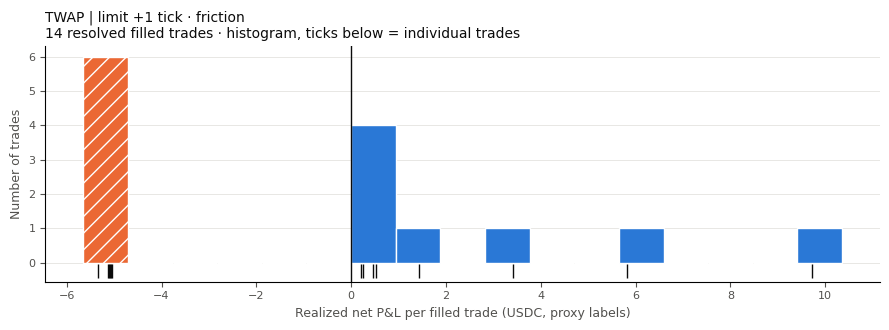

8 of 14 resolved trades were profitable (57%). Average win $2.73, average loss −$5.13: one average loss erases about 1.9 average wins. Largest single loss: −$5.33.


In [12]:
# results-explorer: realized P&L distribution
if seed is not None:
    fig = ex.plot_distribution(rows, title=f'{label} · friction')
    if fig is None:
        print('No resolved filled trades to plot.')
    else:
        plt.show()
    print(ex.distribution_note(metrics))

## Interactive explorer

The controls below need a **running Python kernel**. Run every cell above, then this one. A saved copy of the notebook opened without a kernel shows only the static walkthrough.

**Controls** (changing one filters the cached tables and redraws; nothing reruns):

* **Dataset:** switches between the two saved files. Its scope and limitations box updates with it.
* **Scenario:** `favorable` or `friction`, shown separately.
* **Metric:** total net P&L (default), win rate, average net P&L per resolved fill, or net P&L ÷ spending.
* **Min fills:** hides configurations with fewer resolved fills. The line above the chart says how many remain.
* **Configuration:** a readable label. The full saved configuration is behind it and is used for grouping.
* **Window:** the window to inspect. Its row is shaded on the window chart.
* **Show 5-minute warm-up** (section 6): extends the probability-vs-book chart to the five minutes before the window opens.
* **Generate timeline for this selected run** (section 6, shown only when a run has no saved timeline): replays that one window × configuration × scenario into a separate diagnostic cache, after checking that its configuration, data and scenario still match. It never runs on its own, and a cached timeline reopens without replaying.

The view then shows the comparison bars, the selected configuration's summary and overrides, its window chart and window details, the model probability vs book in the selected window (with a short reading guide), and its P&L distribution.

In [ ]:
# results-explorer: interactive (requires a running kernel and ipywidgets)
try:
    app = ex.Explorer(dataset='validation_seed', scenario='friction')
    display(app.view)
except ImportError:
    print('ipywidgets is not installed: pip install ipywidgets.',
          'The static walkthrough above still applies.')

Saved copy: the controls appear only after this cell is run in a live kernel (Run All).


## Guided exercise

Use the interactive explorer (or the walkthrough above):

1. **Select a configuration.** Start with the corrected model comparison, `friction`, `TWAP | limit +1 tick`.
2. **Check its number of fills** in the summary. How many windows were skipped, and how many orders went unfilled? Remember that neither counts as a loss.
3. **Compare win rate with average win and average loss.** A win rate above 50% can still lose money if the average loss is larger than the average win. Check whether that is the case here.
4. **Inspect individual windows.** Pick a losing window and a winning one. Compare the entry time (seconds remaining), the conservative probability and the fill price. Did the model's estimate differ much from the price it paid?
5. **Switch to `favorable`** with the same configuration. Did the strategy enter in *the same windows*? Did the fills change? Execution assumptions affect which trades happen, not only what they cost. Then switch the dataset to the partial grid and see how few fills each configuration has there.

*Suggested answers depend on the files, which may be updated. What matters is the reasoning: compare counts first, then the shape of the wins and losses, and only then the totals.*

## What none of these charts establish

* **Proxy labels:** outcomes are proxy labels from the recorded payout vector, not qualified settlements.
* **Provisional K:** the opening threshold K is PROVISIONAL.
* **Execution assumptions:** `favorable` and `friction` are explicit, uncalibrated assumptions. `favorable` is not an upper bound on profit.
* **Incomplete grid:** the partial grid was stopped early, covers only a few windows and has no limit buffer.
* **Timing defects:** the partial grid predates the clock correction. Even after the correction, a collector-clock gap still removes some evaluations.
* **Development data only:** the holdout windows have not been evaluated.

**No chart in this notebook shows validated profitability.**